# Bill-text embeddings as a model of what a member believes
**Idea.** Embed each bill (title + CRS summary) with a local sentence-transformer. A member's vector is the vote-weighted average of the embeddings of the bills they voted on:
**Yea = +1, Nay = -1, absent / present = 0 (no relation)**. A Nay therefore pushes the member *away* from a bill's topic, and an absence contributes nothing, which removes the Yea-only / absence problem.

Bill embeddings are centered first (the mean bill is subtracted), so "opposite of the average bill" is what a Nay on a typical bill means. We also subtract the party-mean member vector to isolate what is *idiosyncratic* to the member.

Then: sanity checks (does the vector separate parties? does it match an ideal point? are neighbors sensible?), and whether it helps predict `tilt` (train 115/116, test 118, 117 set aside).

In [1]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr, pearsonr
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)

TRAIN, TEST = [115, 116], 118
CONGS = TRAIN + [TEST]
model = SentenceTransformer("BAAI/bge-small-en-v1.5")      # 33M params, 384-d, runs locally on CPU
model.max_seq_length = 512
print(model)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'cls', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
)


## 1. Bill embeddings
Text = title + CRS summary (latest version). Embeddings are cached in `data/<congress>/bill_emb.npy`.

In [2]:
def bill_embeddings(c):
    info = pd.read_csv(f"data/{c}/bill_info.csv").fillna("")
    f = Path(f"data/{c}/bill_emb.npy")
    if f.exists():
        return info, np.load(f)
    E = model.encode((info.title + ". " + info.summary).tolist(), batch_size=16, normalize_embeddings=True)
    np.save(f, E); return info, E

info, E = {}, {}
for c in CONGS:
    info[c], E[c] = bill_embeddings(c)
    print(c, E[c].shape, f"{(info[c].summary != '').mean():.0%} with a summary, median {info[c].summary.str.split().str.len().median():.0f} words")
info[118][["bill", "title", "policy_area"]].head(4)

115 (429, 384) 100% with a summary, median 141 words
116 (273, 384) 100% with a summary, median 121 words
118 (360, 384) 100% with a summary, median 132 words


,bill,title,policy_area
0,HR23,Family and Small Business Taxpayer Protection Act,Taxation
1,HR26,Born-Alive Abortion Survivors Protection Act,Crime and Law Enforcement
2,HR22,Protecting America’s Strategic Petroleum Reserve from China Act,Energy
3,HR159,Chance to Compete Act of 2023,Government Operations and Politics


## 2. Signed vote matrix
`V[member, bill]` = +1 Yea, -1 Nay, 0 absent/present, for each bill's final House passage vote (Voteview `cast_code`: 1-3 Yea, 4-6 Nay, 7-9 present/not voting).

In [3]:
def vote_matrix(c):
    mem = pd.read_csv(f"data/{c}/voteview/H{c}_members.csv")
    mem = mem[(mem.chamber == "House") & mem.bioguide_id.notna()].drop_duplicates("bioguide_id")
    bills = pd.read_csv(f"data/{c}/bills.csv")[["bill_number", "rollnumber"]]
    votes = pd.read_csv(f"data/{c}/voteview/H{c}_votes.csv")
    votes = votes[votes.chamber == "House"].merge(bills, on="rollnumber")
    votes["v"] = votes.cast_code.map({1: 1, 2: 1, 3: 1, 4: -1, 5: -1, 6: -1}).fillna(0)
    V = (votes.pivot_table(index="icpsr", columns="bill_number", values="v", aggfunc="first")
         .reindex(index=mem.icpsr, columns=info[c].bill).fillna(0))
    V.index = mem.bioguide_id.values
    party = pd.Series(mem.party_code.map({100: "D", 200: "R"}).fillna("O").values, index=V.index)
    names = pd.Series(mem.bioname.values, index=V.index)
    return V, party, names

V, party, names = {}, {}, {}
for c in CONGS:
    V[c], party[c], names[c] = vote_matrix(c)
    v = V[c].values
    print(c, V[c].shape, f"Yea {np.mean(v == 1):.1%}  Nay {np.mean(v == -1):.1%}  absent/none {np.mean(v == 0):.1%}")

115 (450, 429) Yea 75.9%  Nay 14.5%  absent/none 9.7%


116 (448, 273) Yea 74.4%  Nay 17.4%  absent/none 8.2%


118 (451, 360) Yea 70.3%  Nay 21.0%  absent/none 8.7%


## 3. Member vectors
`m_i = sum_b V_ib * (e_b - mean_e) / (# bills member i actually voted on)`.

- **raw** vector: mostly captures party (what each side votes for / against).
- **party-adjusted** vector: raw minus the party mean, i.e. how this member's *issue profile* differs from their party's. Members with fewer than 20 recorded votes are given a zero vector.

In [4]:
MIN_VOTES = 20
def member_vectors(c):
    Ec = E[c] - E[c].mean(0)
    n = np.abs(V[c].values).sum(1)
    M = (V[c].values @ Ec) / np.maximum(n, 1)[:, None]
    M[n < MIN_VOTES] = 0
    Mp = M.copy()
    for p in ["D", "R"]:
        idx = ((party[c] == p).values) & (n >= MIN_VOTES)
        Mp[(party[c] == p).values & (n >= MIN_VOTES)] -= M[idx].mean(0)
    return pd.DataFrame(M, index=V[c].index), pd.DataFrame(Mp, index=V[c].index), pd.Series(n, index=V[c].index)

raw, adj, nvotes = {}, {}, {}
for c in CONGS:
    raw[c], adj[c], nvotes[c] = member_vectors(c)
    print(c, f"{(nvotes[c] >= MIN_VOTES).sum()} of {len(nvotes[c])} members have >= {MIN_VOTES} recorded votes")

115 444 of 450 members have >= 20 recorded votes
116 439 of 448 members have >= 20 recorded votes
118 445 of 451 members have >= 20 recorded votes


## 4. Sanity checks
**(a)** Does the *raw* vector separate the parties? **(b)** Does its main axis match a standard ideal point (1st SVD axis of the signed vote matrix)? **(c)** Are nearest neighbors sensible?

In [5]:
from sklearn.cluster import KMeans
rows = []
for c in CONGS:
    ok = (nvotes[c] >= MIN_VOTES).values & party[c].isin(["D", "R"]).values
    X, y = raw[c].values[ok], (party[c].values[ok] == "R").astype(int)
    pc1 = PCA(2).fit_transform(X)
    km = KMeans(2, n_init=10, random_state=236).fit_predict(X)
    acc = max(np.mean(km == y), np.mean(km != y))
    U, s, _ = np.linalg.svd(V[c].values[ok] - V[c].values[ok].mean(0), full_matrices=False)
    rows.append({"congress": c, "kmeans-2 accuracy vs party": acc, "|corr(emb PC1, vote-matrix SVD1)|": abs(pearsonr(pc1[:, 0], U[:, 0] * s[0])[0]),
                 "|corr(emb PC1, party)|": abs(pearsonr(pc1[:, 0], y)[0])})
pd.DataFrame(rows).set_index("congress").round(3)

,kmeans-2 accuracy vs party,"|corr(emb PC1, vote-matrix SVD1)|","|corr(emb PC1, party)|"
congress,,,
115,0.984,0.957,0.949
116,0.979,0.963,0.956
118,0.989,0.965,0.950


In [6]:
def neighbors(c, query, k=6, vecs=None):
    vecs = adj if vecs is None else vecs
    M = vecs[c]; ok = (nvotes[c] >= MIN_VOTES)
    hit = names[c][names[c].str.contains(query, case=False)].index
    if not len(hit): return None
    X = M.values / np.maximum(np.linalg.norm(M.values, axis=1, keepdims=True), 1e-9)
    sims = pd.Series(X @ X[M.index.get_loc(hit[0])], index=M.index)[ok].drop(hit[0]).nlargest(k)
    return pd.DataFrame({"neighbor": names[c][sims.index].values, "party": party[c][sims.index].values, "cosine": sims.values.round(2)})

for q in ["OCASIO-CORTEZ", "JORDAN, James", "FITZPATRICK", "GOLDEN, Jared"]:
    print("=== party-adjusted neighbors of", q, "(118th)"); print(neighbors(118, q))

=== party-adjusted neighbors of OCASIO-CORTEZ (118th)
           neighbor party  cosine
0       LEE, Summer     D    0.97
1  PRESSLEY, Ayanna     D    0.94
2    RAMIREZ, Delia     D    0.93
3       CASAR, Greg     D    0.91
4       OMAR, Ilhan     D    0.87
5      LEE, Barbara     D    0.87
=== party-adjusted neighbors of JORDAN, James (118th)
None
=== party-adjusted neighbors of FITZPATRICK (118th)
                    neighbor party  cosine
0           MOLINARO, Marcus     R    0.57
1                  COLE, Tom     R    0.53
2  MILLER-MEEKS, Mariannette     R    0.53
3            LAWLER, Michael     R    0.53
4             HINSON, Ashley     R    0.52
5                MILLER, Max     R    0.52
=== party-adjusted neighbors of GOLDEN, Jared (118th)
                   neighbor party  cosine
0  PEREZ, Marie Gluesenkamp     D    0.92
1                DAVIS, Don     D    0.88
2            CUELLAR, Henry     D    0.80
3    GONZALEZ, Vicente, Jr.     D    0.78
4              ROY, Charles     

## 5. What do the main axes mean?
PCA on the party-adjusted member vectors of the training Congresses; each bill embedding is projected onto the axes to show which bills sit at each end.

In [7]:
N_PC = 10
def stack(d, cs): return np.vstack([d[c].values[(nvotes[c] >= MIN_VOTES).values] for c in cs])
pca = PCA(N_PC, random_state=236).fit(stack(adj, TRAIN))
print("explained variance:", pca.explained_variance_ratio_.round(3))
allinfo = pd.concat([info[c].assign(congress=c) for c in CONGS], ignore_index=True)
allE = np.vstack([E[c] for c in CONGS]) - np.vstack([E[c] for c in CONGS]).mean(0)
scores = allE @ pca.components_.T
for k in range(3):
    o = np.argsort(scores[:, k])
    print(f"\n--- PC{k+1}: high end"); print(allinfo.iloc[o[-4:]][["congress", "bill", "title"]].assign(title=lambda x: x.title.str[:100]).to_string(index=False))
    print(f"--- PC{k+1}: low end");  print(allinfo.iloc[o[:4]][["congress", "bill", "title"]].assign(title=lambda x: x.title.str[:100]).to_string(index=False))

explained variance: [0.203 0.127 0.067 0.061 0.054 0.041 0.036 0.03  0.02  0.018]



--- PC1: high end
 congress     bill                                                                                                title
      115  HJRES67 Disapproving the rule submitted by the Department of Labor relating to savings arrangements establis
      115 HJRES111 Providing for congressional disapproval under chapter 8 of title 5, United States Code, of the rule 
      115    HR720                                                                  Lawsuit Abuse Reduction Act of 2017
      115    HR657                                                                                 Follow the Rules Act
--- PC1: low end
 congress   bill                                                                                                title
      115    HR2                                                                  Agriculture Improvement Act of 2018
      116 HR4031                                                                                     GLRI Act of 2019
      115 

## 6. Does it help predict `tilt`?
Features per member (z-scored within each Congress):
- **baseline:** party, previous two-party share (regression to the mean was the one real signal before).
- **true disloyalty** (now possible with Nays): `n_cross` = recorded votes against the member's own party on bills where the party was at least 75/25 on one side, and `cross_rate` = that over the member's recorded votes.
- **emb PCs:** the 10 PCA scores of the *party-adjusted* member vector (PCA fit on training Congresses only).
- **issue profile:** mean signed vote within each policy area, party-adjusted (an interpretable cousin of the embedding).

In [8]:
targets = pd.read_csv("data/elections/targets.csv")

def disloyalty(c):
    v, p = V[c].values, party[c].values
    n_cross, n_line = np.zeros(len(v)), np.zeros(len(v))
    for q in ["D", "R"]:
        m = p == q
        tot, pres = v[m].sum(0), np.abs(v[m]).sum(0)
        line = (pres > 0) & (np.abs(tot) / np.maximum(pres, 1) >= 0.5)         # party at least 75/25
        maj = np.sign(tot)
        n_cross[m] = ((v[m] != 0) & (v[m] != maj) & line).sum(1)
        n_line[m] = ((v[m] != 0) & line).sum(1)
    return pd.DataFrame({"n_cross": np.log1p(n_cross), "cross_rate": n_cross / np.maximum(n_line, 1)}, index=V[c].index)

areas = pd.concat([info[c].policy_area for c in CONGS]).value_counts()
AREAS = areas.index[:12].tolist()
def issue_profile(c):
    P = np.column_stack([(info[c].policy_area == a).values for a in AREAS]).astype(float)
    prof = (V[c].values @ P) / np.maximum(P.sum(0), 1)
    out = pd.DataFrame(prof, index=V[c].index, columns=["pol_" + a[:14].replace(" ", "_") for a in AREAS])
    ok = (nvotes[c] >= MIN_VOTES).values
    for q in ["D", "R"]:
        m = (party[c] == q).values & ok
        out[m] = out[m] - out[m].mean(0)
    out[~ok] = 0
    return out

pcs = lambda c, a: pd.DataFrame(pca.transform(a[c].values), index=a[c].index, columns=[f"{n}{k+1}" for n, k in [("emb_adj_pc", k) for k in range(N_PC)]])
rawpca = PCA(N_PC, random_state=236).fit(stack(raw, TRAIN))
pcr = lambda c: pd.DataFrame(rawpca.transform(raw[c].values), index=raw[c].index, columns=[f"emb_raw_pc{k+1}" for k in range(N_PC)])

feats = pd.concat([pd.concat([disloyalty(c), pcs(c, adj), pcr(c), issue_profile(c)], axis=1).assign(congress=c).rename_axis("bioguide").reset_index() for c in CONGS])
G_DIS = ["n_cross", "cross_rate"]
G_PC = [c for c in feats.columns if c.startswith("emb_adj_pc")]
G_RAWPC = [c for c in feats.columns if c.startswith("emb_raw_pc")]
G_POL = [c for c in feats.columns if c.startswith("pol_")]
ALL = G_DIS + G_PC + G_RAWPC + G_POL

d = targets.merge(feats, on=["congress", "bioguide"])
d = d[d.tilt.notna() & d.party.isin(["D", "R"])].copy()
d["tilt_c"] = d.tilt - d.groupby(["congress", "party"]).tilt.transform("mean")
d["is_R"] = (d.party == "R").astype(float)
d["prev_share"] = d.prev_two_party_share
z = lambda x: (x - x.mean()) / x.std()
d[ALL + ["prev_share"]] = d.groupby("congress")[ALL + ["prev_share"]].transform(z)
d[ALL] = d[ALL].fillna(0)
print(d.groupby("congress").size().to_dict(), "rows")

{115: 281, 116: 327, 118: 320} rows


C:\Users\1980h\AppData\Local\Temp\ipykernel_18712\3508953566.py:24: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  out[m] = out[m] - out[m].mean(0)
C:\Users\1980h\AppData\Local\Temp\ipykernel_18712\3508953566.py:24: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  out[m] = out[m] - out[m].mean(0)
C:\Users\1980h\AppData\Local\Temp\ipykernel_18712\3508953566.py:24: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  out[m] = out[m] - out[m].mean(0)
C:\Users\1980h\AppData\Local\Temp\ipykernel_18712\3508953566.py:24: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  out[m] = out[m] - out[m].mean(0)
C:\Users\1980h\AppData\Local\Temp\ipykernel_18712\3508953566.py:24: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  out[m] = out[m] - out[m].mean(0)
C:\Users\1980h\AppDa

### 6a. Univariate: Spearman correlation with `tilt_c`, by Congress (is the sign stable?)

In [9]:
rows = []
for f_ in G_DIS + G_PC + G_RAWPC + G_POL + ["prev_share"]:
    r = {"feature": f_}
    for c in CONGS:
        s = d[d.congress == c]; r[c] = spearmanr(s[f_], s.tilt_c)[0]
    rows.append(r)
uni = pd.DataFrame(rows).set_index("feature")
uni["same_sign"] = (np.sign(uni[115]) == np.sign(uni[116])) & (np.sign(uni[116]) == np.sign(uni[118]))
uni["mean_abs"] = uni[CONGS].abs().mean(axis=1)
uni.sort_values("mean_abs", ascending=False).head(14).round(3)

,115,116,118,same_sign,mean_abs
feature,,,,,
prev_share,-0.103,-0.198,-0.289,True,0.197
pol_Government_Ope,0.115,0.237,0.078,True,0.143
pol_Armed_Forces_a,0.084,0.165,0.152,True,0.134
pol_Health,0.108,0.126,0.095,True,0.110
cross_rate,-0.046,-0.159,-0.124,True,0.110
pol_Commerce,0.012,0.209,0.103,True,0.108
n_cross,-0.041,-0.154,-0.123,True,0.106
pol_Economics_and_,-0.033,0.196,0.083,False,0.104
"pol_Science,_Techn",0.213,0.014,0.069,True,0.099


### 6b. Models
Ridge, penalty chosen by leave-one-Congress-out on 115/116, scored on 118 (`oos R2` vs the training mean; 0 = no better than a constant).

In [10]:
def ridge(X, y, lam):
    mu, ym = X.mean(0), y.mean()
    beta = np.linalg.solve((X - mu).T @ (X - mu) + lam * np.eye(X.shape[1]), (X - mu).T @ (y - ym))
    return (lambda Xn: ym + (Xn - mu) @ beta), beta

def run(cols, target):
    tr, te = d[d.congress.isin(TRAIN)], d[d.congress == TEST]
    cv = {lam: sum(((b[target].values - ridge(a[cols].values, a[target].values, lam)[0](b[cols].values)) ** 2).sum()
                   for a, b in [(tr[tr.congress != h], tr[tr.congress == h]) for h in TRAIN]) for lam in [1, 10, 100, 1000, 10000]}
    lam = min(cv, key=cv.get)
    pred, beta = ridge(tr[cols].values, tr[target].values, lam)
    p, y = pred(te[cols].values), te[target].values
    sse0 = ((y - tr[target].mean()) ** 2).sum()
    return {"lambda": lam, "oos R2": 1 - ((y - p) ** 2).sum() / sse0, "test corr": pearsonr(p, y)[0], "test RMSE": np.sqrt(((y - p) ** 2).mean())}, p, beta

BASE = ["is_R", "prev_share"]
sets = {"baseline (party + prev share)": BASE, "baseline + disloyalty": BASE + G_DIS,
        "baseline + emb PCs (party-adj)": BASE + G_PC, "baseline + emb PCs (raw)": BASE + G_RAWPC,
        "baseline + issue profile": BASE + G_POL, "baseline + everything": BASE + ALL,
        "emb PCs (party-adj) only": G_PC, "issue profile only": G_POL}
res, store = [], {}
for target in ["tilt", "tilt_c"]:
    for name, cols in sets.items():
        m, p, beta = run(cols, target); store[(target, name)] = (p, beta, cols)
        res.append({"target": target, "features": name, **m})
pd.DataFrame(res).set_index(["target", "features"]).round(3)

lambda  oos R2  test corr  test RMSE
target features                                                            
tilt   baseline (party + prev share)    10000   0.007      0.272      0.027
       baseline + disloyalty            10000   0.006      0.199      0.027
       baseline + emb PCs (party-adj)   10000   0.007      0.201      0.027
       baseline + emb PCs (raw)           100  -0.063      0.181      0.028
       baseline + issue profile         10000   0.008      0.129      0.027
       baseline + everything             1000   0.035      0.196      0.027
       emb PCs (party-adj) only         10000   0.000      0.018      0.027
       issue profile only               10000   0.002      0.044      0.027
tilt_c baseline (party + prev share)       10   0.077      0.286      0.025
       baseline + disloyalty              100   0.087      0.307      0.025
       baseline + emb PCs (party-adj)     100   0.055      0.236      0.025
       baseline + emb PCs (raw)           100   0.030      0.191      0.026
       baseline + issue profile          1000   0.032      0.186      0.026
       baseline + everything             1000   0.027      0.166      0.026
       emb PCs (party-adj) only         10000   0.000      0.020      0.026
       issue profile only               10000   0.002      0.043      0.026

### 6c. The member space, and the test-year fit

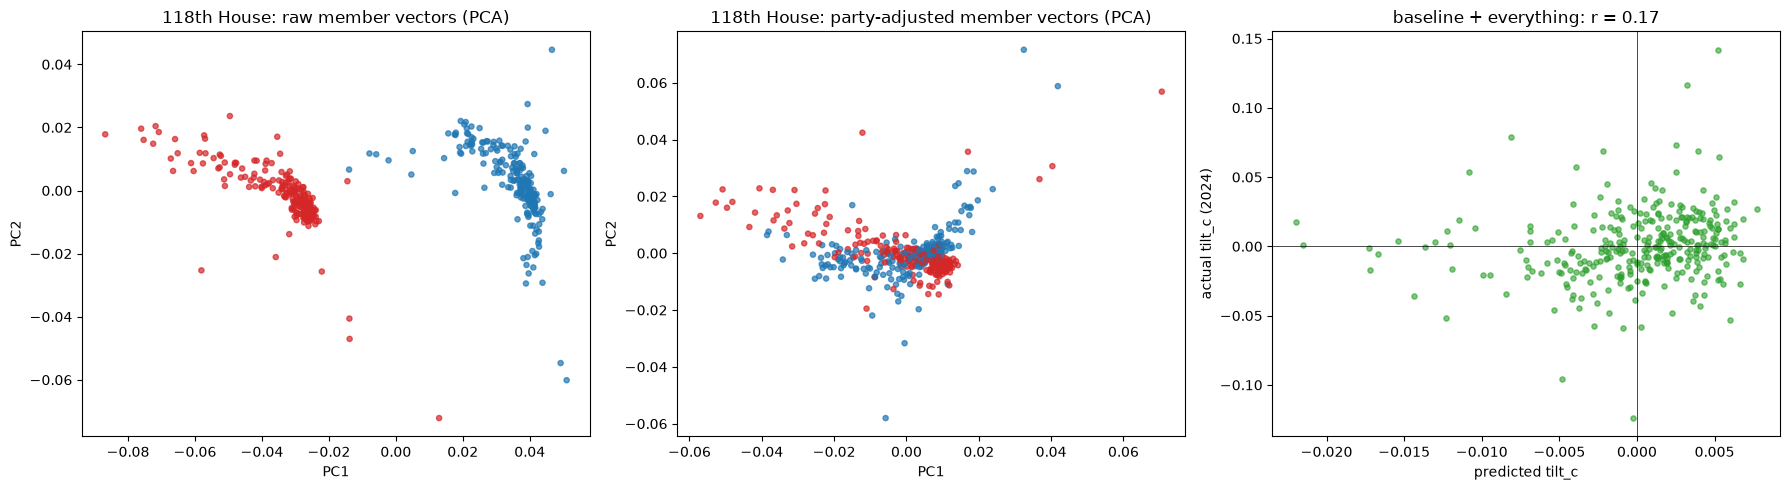

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
c = TEST; ok = (nvotes[c] >= MIN_VOTES).values & party[c].isin(["D", "R"]).values
col = np.where(party[c].values[ok] == "R", "#d62728", "#1f77b4")
for a, (M, title) in zip(ax[:2], [(raw[c], "raw member vectors"), (adj[c], "party-adjusted member vectors")]):
    xy = PCA(2, random_state=236).fit_transform(M.values[ok])
    a.scatter(xy[:, 0], xy[:, 1], c=col, s=14, alpha=0.7); a.set(title=f"118th House: {title} (PCA)", xlabel="PC1", ylabel="PC2")
p = store[("tilt_c", "baseline + everything")][0]; te = d[d.congress == TEST]
ax[2].scatter(p, te.tilt_c, s=14, alpha=0.6, c="#2ca02c"); ax[2].axhline(0, c="k", lw=0.5); ax[2].axvline(0, c="k", lw=0.5)
ax[2].set(xlabel="predicted tilt_c", ylabel="actual tilt_c (2024)", title=f"baseline + everything: r = {pearsonr(p, te.tilt_c)[0]:.2f}")
plt.tight_layout(); plt.show()

## What we notice
1. **The embedding is a sensible model of the member.** The raw vectors split the parties with 98-99% accuracy (2-means, no labels), PC1 correlates 0.96 with the 1st SVD axis of the signed vote matrix (an ideal point), and neighbors make sense: AOC's nearest are Summer Lee, Pressley, Ramirez, Casar, Omar; Jared Golden's are Marie Gluesenkamp Perez, Don Davis, Cuellar, Gonzalez (Blue Dogs), plus Chip Roy at 0.78 after party adjustment.
2. **But the main axes are bill *genre*, not issue.** PC1 contrasts Congressional Review Act disapproval resolutions / regulatory bills with agriculture and appropriations; PC2 contrasts continuing resolutions with small bipartisan cybersecurity / veterans bills; PC3 contrasts CRA disapprovals with omnibus / supplemental appropriations. Most of the variance in what gets voted on is *kind of bill* (must-pass vs messaging vs consensus), which is what a floor agenda produces. Issue content is a smaller, later component.
3. **The embeddings do not help predict tilt.** Baseline (party + prev share) has oos R2 0.077 on `tilt_c`; adding party-adjusted PCs gives 0.055, raw PCs 0.030, issue profile 0.032, everything 0.027. On the realistic `tilt` target all are ~0.01-0.04. Embeddings alone are ~0.
4. **True disloyalty (now measurable with Nays) has a stable sign.** `cross_rate` / `n_cross` correlate -0.05, -0.16, -0.12 with `tilt_c` in 2018 / 2020 / 2024: members who more often vote against a party-line majority do slightly *worse* than their party peers. (The Yea-only version earlier was unstable.) Adding it to the baseline moves `tilt_c` R2 from 0.077 to 0.087: suggestive, not significant with one test year.
5. **Caveats.** One test year, ~320 members, R2 differences of 0.01 are noise. `tilt_c` removes the (congress, party) mean using the test year's own targets, so it is the optimistic target; the raw `tilt` shows ~0 for everything but the baseline.

**Next:** use embeddings for description (who is an outlier within a party on which topic) rather than prediction; remove the "bill genre" axes (e.g. regress them out, or restrict to non-appropriations / non-CRA bills) so the remaining variance is issue content; add district partisanship so issue profile can interact with what the district wants.

## 7. Embeddings as high-dimensional input to XGBoost
Can the nonlinear model find structure in the member vectors that the linear ridge on 10 PCs could not? We give XGBoost: the baseline + disloyalty, then add the party-adjusted member embedding at three resolutions (10 PCs, 50 PCs, the full 384 dimensions). Same split as before: hyperparameters chosen by leave-one-Congress-out on 115/116, scored on 118. For comparison, a ridge on the full 384 dimensions.

In [12]:
from itertools import product
from xgboost import XGBRegressor

tr, te = d[d.congress.isin(TRAIN)].reset_index(drop=True), d[d.congress == TEST].reset_index(drop=True)
emb = lambda df: np.vstack([adj[c].loc[b].values for c, b in zip(df.congress, df.bioguide)])
Etr, Ete = emb(tr), emb(te)
pca50 = PCA(50, random_state=236).fit(stack(adj, TRAIN))
LOW = BASE + G_DIS
blocks = {  # name -> (train matrix, test matrix)
    "baseline + disloyalty": (tr[LOW].values, te[LOW].values),
    "+ 10 PCs": (np.hstack([tr[LOW].values, pca.transform(Etr)]), np.hstack([te[LOW].values, pca.transform(Ete)])),
    "+ 50 PCs": (np.hstack([tr[LOW].values, pca50.transform(Etr)]), np.hstack([te[LOW].values, pca50.transform(Ete)])),
    "+ full 384-d": (np.hstack([tr[LOW].values, Etr]), np.hstack([te[LOW].values, Ete])),
    "full 384-d only": (Etr, Ete),
}
GRID = [dict(max_depth=m, n_estimators=n) for m, n in product([1, 2, 3], [100, 300])]
mk = lambda **g: XGBRegressor(learning_rate=0.03, subsample=0.7, colsample_bytree=0.3, min_child_weight=10,
                              reg_lambda=10, random_state=236, n_jobs=-1, **g)

def xgb_eval(Xtr, Xte, target):
    y, yt = tr[target].values, te[target].values
    cv = {}
    for i, g in enumerate(GRID):
        sse = 0
        for h in TRAIN:
            a, b = (tr.congress != h).values, (tr.congress == h).values
            sse += ((y[b] - mk(**g).fit(Xtr[a], y[a]).predict(Xtr[b])) ** 2).sum()
        cv[i] = sse
    g = GRID[min(cv, key=cv.get)]
    p = mk(**g).fit(Xtr, y).predict(Xte)
    sse0 = ((yt - y.mean()) ** 2).sum()
    return {**g, "oos R2": 1 - ((yt - p) ** 2).sum() / sse0, "test corr": pearsonr(p, yt)[0], "test RMSE": np.sqrt(((yt - p) ** 2).mean())}

rows = []
for target in ["tilt", "tilt_c"]:
    for name, (Xa, Xb) in blocks.items():
        rows.append({"target": target, "model": "xgboost", "features": name, **xgb_eval(Xa, Xb, target)})
    # linear comparison: ridge on baseline + disloyalty + full embedding (standardised)
    mu, sd = np.hstack([blocks["+ full 384-d"][0]]).mean(0), blocks["+ full 384-d"][0].std(0) + 1e-9
    Xa, Xb = (blocks["+ full 384-d"][0] - mu) / sd, (blocks["+ full 384-d"][1] - mu) / sd
    y, yt = tr[target].values, te[target].values
    cv = {lam: sum(((y[(tr.congress == h).values] - ridge(Xa[(tr.congress != h).values], y[(tr.congress != h).values], lam)[0](Xa[(tr.congress == h).values])) ** 2).sum() for h in TRAIN)
          for lam in [10, 100, 1000, 10000, 100000]}
    lam = min(cv, key=cv.get); p = ridge(Xa, y, lam)[0](Xb)
    sse0 = ((yt - y.mean()) ** 2).sum()
    rows.append({"target": target, "model": "ridge", "features": "+ full 384-d", "lambda": lam, "oos R2": 1 - ((yt - p) ** 2).sum() / sse0,
                 "test corr": pearsonr(p, yt)[0], "test RMSE": np.sqrt(((yt - p) ** 2).mean())})
pd.DataFrame(rows).set_index(["target", "model", "features"]).round(3)

max_depth  n_estimators  oos R2  test corr  test RMSE    lambda
target model   features                                                                              
tilt   xgboost baseline + disloyalty        1.0         100.0   0.016      0.121      0.027       NaN
               + 10 PCs                     1.0         100.0   0.017      0.069      0.027       NaN
               + 50 PCs                     3.0         100.0  -0.018      0.016      0.027       NaN
               + full 384-d                 1.0         100.0  -0.025     -0.065      0.027       NaN
               full 384-d only              1.0         100.0  -0.026     -0.097      0.027       NaN
       ridge   + full 384-d                 NaN           NaN  -0.001      0.023      0.027  100000.0
tilt_c xgboost baseline + disloyalty        1.0         100.0   0.037      0.196      0.025       NaN
               + 10 PCs                     1.0         100.0   0.028      0.169      0.026       NaN
               + 50 PCs                     2.0         100.0   0.017      0.151      0.026       NaN
               + full 384-d                 1.0         100.0  -0.002      0.075      0.026       NaN
               full 384-d only              1.0         100.0  -0.036      0.016      0.026       NaN
       ridge   + full 384-d                 NaN           NaN   0.001      0.033      0.026  100000.0

### Result of section 7
- **High-dimensional embeddings hurt, they do not help.** The more embedding dimensions XGBoost sees, the worse the test score: on `tilt_c`, baseline + disloyalty 0.037, + 10 PCs 0.028, + 50 PCs 0.017, + full 384-d -0.002, 384-d alone -0.036. On raw `tilt` the full embedding is negative (-0.025). A ridge on the full 384-d is ~0.
- **Cross-validation picks the simplest model every time** (depth 1 or 2, 100 trees) for the embedding sets: there is no nonlinear structure for deeper trees to exploit in ~600 rows.
- **Why:** 384 dimensions on ~600 members with a target that is mostly noise (SD about 0.026), and the embedding variance is dominated by bill genre and party rather than anything that tracks electoral over/under-performance.
- **Where nuance could still come from:** interactions with the district (issue profile x district lean), more Congresses, or a different target; not from squeezing more out of the member vector alone.

## 8. Follow-up: disloyalty direction, and baseline + disloyalty + party-adjusted PCs with ridge

In [13]:
# (i) the exact combination, with the linear model
res = []
for target in ["tilt", "tilt_c"]:
    for name, cols in {"baseline + disloyalty": BASE + G_DIS,
                       "baseline + disloyalty + 3 party-adj PCs": BASE + G_DIS + G_PC[:3],
                       "baseline + disloyalty + 10 party-adj PCs": BASE + G_DIS + G_PC}.items():
        m, p, beta = run(cols, target); res.append({"target": target, "features": name, **m})
print(pd.DataFrame(res).set_index(["target", "features"]).round(3))

# (ii) which way does disloyalty point? ridge coefficients on z-scored features, fit on the training Congresses
for target in ["tilt", "tilt_c"]:
    m, p, beta = run(BASE + G_DIS, target)
    print(target, "(target SD %.3f):" % d[target].std(), dict(zip(BASE + G_DIS, beta.round(4))))

# (iii) correlation of cross_rate with tilt_c, raw and after removing prev_share, by party and congress
resid = lambda y, x: y - np.polyval(np.polyfit(x, y, 1), x)
rows = []
for c in CONGS:
    for p_ in ["D", "R"]:
        s = d[(d.congress == c) & (d.party == p_)]
        rows.append({"congress": c, "party": p_, "n": len(s),
                     "rho(cross_rate, tilt_c)": spearmanr(s.cross_rate, s.tilt_c)[0],
                     "partial corr (ctrl prev_share)": pearsonr(resid(s.cross_rate.values, s.prev_share.values),
                                                                resid(s.tilt_c.values, s.prev_share.values))[0]})
pd.DataFrame(rows).set_index(["congress", "party"]).round(3)

                                                 lambda  oos R2  test corr  test RMSE
target features                                                                      
tilt   baseline + disloyalty                      10000   0.006      0.199      0.027
       baseline + disloyalty + 3 party-adj PCs    10000   0.007      0.228      0.027
       baseline + disloyalty + 10 party-adj PCs   10000   0.006      0.199      0.027
tilt_c baseline + disloyalty                        100   0.087      0.307      0.025
       baseline + disloyalty + 3 party-adj PCs      100   0.081      0.293      0.025
       baseline + disloyalty + 10 party-adj PCs    1000   0.038      0.206      0.025
tilt (target SD 0.033): {'is_R': np.float64(0.0001), 'prev_share': np.float64(-0.0004), 'n_cross': np.float64(0.0001), 'cross_rate': np.float64(0.0001)}


tilt_c (target SD 0.030): {'is_R': np.float64(-0.0004), 'prev_share': np.float64(-0.0052), 'n_cross': np.float64(-0.0028), 'cross_rate': np.float64(-0.0003)}


n  rho(cross_rate, tilt_c)  partial corr (ctrl prev_share)
congress party                                                              
115      D      117                   -0.012                          -0.110
         R      164                   -0.062                           0.004
116      D      177                   -0.176                          -0.301
         R      150                   -0.110                          -0.157
118      D      158                   -0.171                          -0.232
         R      162                   -0.067                           0.006

### Result of section 8
- **Disloyalty points the "bad" way, weakly.** More votes against a party-line majority goes with slightly *lower* tilt relative to party peers. Controlling for prev_share, the partial correlation is -0.11 / -0.30 / -0.23 for Democrats (2018 / 2020 / 2024) but about 0 / -0.16 / 0.01 for Republicans, so the pattern is mainly a Democratic one and not very stable. Effect size is small (ridge coefficient on `n_cross` about -0.003 per SD, vs a target SD of 0.03).
- **Baseline + disloyalty + party-adjusted PCs does not beat baseline + disloyalty.** `tilt_c` oos R2: 0.087 (no PCs), 0.081 (3 PCs), 0.038 (10 PCs). On raw `tilt`: 0.006 / 0.007 / 0.006.
- Correlational only; we have not tested whether the sign differs between swing and safe seats.

## 9. Should Democrats and Republicans get separate models?
So far one pooled model: `is_R` shifts the intercept only, and every feature has the *same* coefficient for both parties. Constituents (and so what helps or hurts a member) may differ by party. Here we fit separate ridge models per party (penalty by leave-one-Congress-out within party) and compare with the pooled model on the 118th.

In [14]:
def fit_party(cols, target, party_):
    tr_p = d[d.congress.isin(TRAIN) & (d.party == party_)]
    cv = {lam: sum(((b[target].values - ridge(a[cols].values, a[target].values, lam)[0](b[cols].values)) ** 2).sum()
                   for a, b in [(tr_p[tr_p.congress != h], tr_p[tr_p.congress == h]) for h in TRAIN]) for lam in [1, 10, 100, 1000, 10000]}
    lam = min(cv, key=cv.get)
    f, beta = ridge(tr_p[cols].values, tr_p[target].values, lam)
    return f, beta, lam, tr_p[target].mean()

rows, coefs = [], {}
te = d[d.congress == TEST]
for target in ["tilt_c", "tilt"]:
    for name, cols in {"prev share + disloyalty": ["prev_share"] + G_DIS,
                       "+ 3 party-adj PCs": ["prev_share"] + G_DIS + G_PC[:3],
                       "+ issue profile": ["prev_share"] + G_DIS + G_POL}.items():
        pooled, _, _ = run(["is_R"] + cols, target)
        p_all = np.zeros(len(te)); out = {"target": target, "features": name, "pooled oos R2": pooled["oos R2"]}
        for q in ["D", "R"]:
            f, beta, lam, mu = fit_party(cols, target, q)
            m = (te.party == q).values
            p_all[m] = f(te[cols].values[m])
            y = te[target].values[m]
            out[f"{q} separate R2"] = 1 - ((y - p_all[m]) ** 2).sum() / ((y - mu) ** 2).sum()
            coefs[(target, name, q)] = pd.Series(beta, index=cols)
        sse0 = ((te[target].values - d[d.congress.isin(TRAIN)][target].mean()) ** 2).sum()
        out["separate (both parties) oos R2"] = 1 - ((te[target].values - p_all) ** 2).sum() / sse0
        rows.append(out)
print(pd.DataFrame(rows).set_index(["target", "features"]).round(3))
print("\nCoefficients (z-scored features), prev share + disloyalty, tilt_c:")
print(pd.DataFrame({q: coefs[("tilt_c", "prev share + disloyalty", q)] for q in ["D", "R"]}).round(4))

                                pooled oos R2  D separate R2  R separate R2  separate (both parties) oos R2
target features                                                                                            
tilt_c prev share + disloyalty          0.087          0.134          0.018                           0.096
       + 3 party-adj PCs                0.081          0.127          0.001                           0.086
       + issue profile                  0.037          0.049         -0.017                           0.028
tilt   prev share + disloyalty          0.006          0.107         -0.000                           0.051
       + 3 party-adj PCs                0.007          0.101          0.000                           0.047
       + issue profile                  0.007          0.037          0.000                           0.000

Coefficients (z-scored features), prev share + disloyalty, tilt_c:
                 D       R
prev_share -0.0054 -0.0032
n_cross    -0.

### Result of section 9
- **Separate models help a little, almost entirely for Democrats.** `tilt_c`: pooled 0.087 -> separate 0.096 (D 0.134, R 0.018). Raw `tilt`: pooled 0.006 -> separate 0.051 (D 0.107, R 0.000).
- **Coefficients have the same signs in both parties** (prev share negative, disloyalty negative) but are larger for Democrats: prev_share -0.0054 vs -0.0032, n_cross -0.0026 vs -0.0018, cross_rate -0.0017 vs -0.0003.
- **Adding PCs or the issue profile still does not help in either party.**
- Caveat: one test year, ~160 members per party; the Democratic gain is suggestive, not established.